In [24]:
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.nn.functional as F
from torchvision.datasets import CIFAR100
from torchvision.datasets import CIFAR10
import torchvision.transforms as tt
from torchvision.utils import make_grid
from torch.utils.data.dataloader import DataLoader
from torch.utils.data import random_split,ConcatDataset

%matplotlib inline

In [25]:
project_name = "cifar100"
import os
os.environ["CUDA_VISIBLE_DEVICES"] = str(0)

In [26]:
stats = ((0.5074,0.4867,0.4411),(0.2011,0.1987,0.2025))
train_transform = tt.Compose([
    tt.RandomHorizontalFlip(),
    tt.RandomCrop(32,padding=4,padding_mode="reflect"),
    tt.ToTensor(),
    tt.Normalize(*stats)
])

test_transform = tt.Compose([
    tt.ToTensor(),
    tt.Normalize(*stats)
])

In [27]:
train_data = CIFAR10(download=True,root="./data",transform=train_transform)
test_data = CIFAR10(root="./data",train=False,transform=test_transform)

Files already downloaded and verified


In [28]:
for image,label in train_data:
    print("Image shape: ",image.shape)
    print("Image tensor: ", image)
    print("Label: ", label)
    break

Image shape:  torch.Size([3, 32, 32])
Image tensor:  tensor([[[-1.7821, -1.8796, -1.7821,  ...,  0.0120, -0.0855, -0.1636],
         [-2.2111, -2.0356, -2.2111,  ...,  0.0120, -0.2221, -0.1831],
         [-2.5231, -2.2111, -2.5231,  ...,  0.0705, -0.1246, -0.2026],
         ...,
         [ 1.1235,  1.4160,  1.1235,  ...,  0.8115,  1.6695,  1.1040],
         [ 1.2405,  1.6890,  1.2405,  ...,  1.4355,  1.4940, -0.1050],
         [ 1.3965,  1.7670,  1.3965,  ...,  1.1040,  0.8505, -1.4311]],

        [[-2.0547, -1.9560, -2.0547,  ..., -0.6732, -0.7324, -0.7719],
         [-2.3113, -1.9758, -2.3113,  ..., -0.5942, -0.7916, -0.7916],
         [-2.4494, -2.0547, -2.4494,  ..., -0.5548, -0.7126, -0.8113],
         ...,
         [ 0.0965,  0.6492,  0.0965,  ...,  0.1360,  1.1623,  0.6097],
         [ 0.2347,  0.9847,  0.2347,  ...,  0.8465,  0.9649, -0.6140],
         [ 0.5110,  1.1426,  0.5110,  ...,  0.6097,  0.3926, -1.8771]],

        [[-2.1008, -1.8491, -2.1008,  ..., -1.2100, -1.2100, -1

In [29]:
train_data.classes

['airplane',
 'automobile',
 'bird',
 'cat',
 'deer',
 'dog',
 'frog',
 'horse',
 'ship',
 'truck']

In [30]:
# train_classes_items = dict()

# for train_item in train_data:
#     label = train_data.classes[train_item[1]]
#     if label not in train_classes_items:
#         train_classes_items[label] = 1
#     else:
#         train_classes_items[label] += 1

# train_classes_items
        

In [31]:
# test_classes_items = dict()
# for test_item in test_data:
#     label = test_data.classes[test_item[1]]
#     if label not in test_classes_items:
#         test_classes_items[label] = 1
#     else:
#         test_classes_items[label] += 1

# test_classes_items

In [32]:
BATCH_SIZE=128
train_dl = DataLoader(train_data,BATCH_SIZE,num_workers=4,pin_memory=True,shuffle=True)
test_dl = DataLoader(test_data,BATCH_SIZE,num_workers=4,pin_memory=True)

In [33]:
def show_batch(dl):
    for batch in dl:
        images,labels = batch
        fig, ax = plt.subplots(figsize=(7.5,7.5))
        ax.set_yticks([])
        ax.set_xticks([])
        ax.imshow(make_grid(images[:20],nrow=5).permute(1,2,0))
        break

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


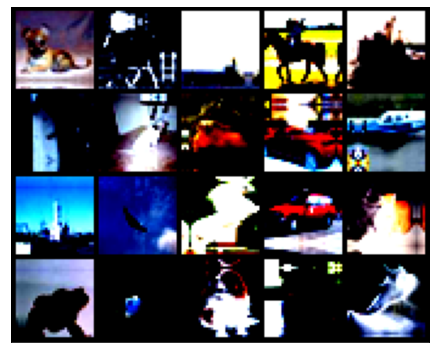

In [34]:
show_batch(train_dl)

In [35]:
def get_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    return torch.device("cpu")

def to_device(data,device):
    if isinstance(data,(list,tuple)):
        return [to_device(x,device) for x in data]
    return data.to(device,non_blocking=True)


class ToDeviceLoader:
    def __init__(self,data,device):
        self.data = data
        self.device = device
        
    def __iter__(self):
        for batch in self.data:
            yield to_device(batch,self.device)
            
    def __len__(self):
        return len(self.data)


In [36]:
device = get_device()
print(device)

train_dl = ToDeviceLoader(train_dl,device)
test_dl = ToDeviceLoader(test_dl,device)

cuda


In [37]:
def accuracy(predicted,actual):
    _, predictions = torch.max(predicted,dim=1)
    return torch.tensor(torch.sum(predictions==actual).item()/len(predictions))

class BaseModel(nn.Module):
    def training_step(self,batch):
        images,labels = batch
        out = self(images)
        loss = F.cross_entropy(out,labels)
        return loss
    
    def validation_step(self,batch):
        images,labels = batch
        out = self(images)
        loss = F.cross_entropy(out,labels)
        acc = accuracy(out,labels)
        return {"val_loss":loss.detach(),"val_acc":acc}
    
    def validation_epoch_end(self,outputs):
        batch_losses = [loss["val_loss"] for loss in outputs]
        loss = torch.stack(batch_losses).mean()
        batch_accuracy = [accuracy["val_acc"] for accuracy in outputs]
        acc = torch.stack(batch_accuracy).mean()
        return {"val_loss":loss.item(),"val_acc":acc.item()}
    
    def epoch_end(self, epoch, result):
        print("Epoch [{}], last_lr: {:.5f}, train_loss: {:.4f}, val_loss: {:.4f}, val_acc: {:.4f}".format(
            epoch, result['lrs'][-1], result['train_loss'], result['val_loss'], result['val_acc']))
        
        

In [38]:
def conv_shortcut(in_channel,out_channel,stride):
    layers = [nn.Conv2d(in_channel,out_channel,kernel_size=(1,1),stride=(stride,stride)),
             nn.BatchNorm2d(out_channel)]
    return nn.Sequential(*layers)

def block(in_channel,out_channel,k_size,stride, conv=False):
    layers = None
    
    first_layers = [nn.Conv2d(in_channel,out_channel[0],kernel_size=(1,1),stride=(1,1)),
                    nn.BatchNorm2d(out_channel[0]),
                    nn.ReLU(inplace=True)]
    if conv:
        first_layers[0].stride=(stride,stride)
    
    second_layers = [nn.Conv2d(out_channel[0],out_channel[1],kernel_size=(k_size,k_size),stride=(1,1),padding=1),
                    nn.BatchNorm2d(out_channel[1])]

    layers = first_layers + second_layers
    
    return nn.Sequential(*layers)
    

class Resnet50(BaseModel):
    
    def __init__(self,in_channels,num_classes):
        super().__init__()
        
        self.stg1 = nn.Sequential(
                                   nn.Conv2d(in_channels=in_channels,out_channels=64,kernel_size=(3),stride=(1),padding=1),
                                   nn.BatchNorm2d(64),
                                   nn.ReLU(inplace=True),
                                   nn.MaxPool2d(kernel_size=3,stride=2))
        
        ##stage 2
        self.convShortcut2 = conv_shortcut(64,256,1)
        
        self.conv2 = block(64,[64,256],3,1,conv=True)
        self.ident2 = block(256,[64,256],3,1)

        
        ##stage 3
        self.convShortcut3 = conv_shortcut(256,512,2)
        
        self.conv3 = block(256,[128,512],3,2,conv=True)
        self.ident3 = block(512,[128,512],3,2)

        
        ##stage 4
        self.convShortcut4 = conv_shortcut(512,1024,2)
        
        self.conv4 = block(512,[256,1024],3,2,conv=True)
        self.ident4 = block(1024,[256,1024],3,2)
        
        
        ##Classify
        self.classifier = nn.Sequential(
                                       nn.AvgPool2d(kernel_size=(4)),
                                       nn.Flatten(),
                                       nn.Linear(1024,num_classes))
        
    def forward(self,inputs):
        out = self.stg1(inputs)
        
        #stage 2
        out = F.relu(self.conv2(out) + self.convShortcut2(out))
        out = F.relu(self.ident2(out) + out)
        out = F.relu(self.ident2(out) + out)
        
        #stage3
        out = F.relu(self.conv3(out) + (self.convShortcut3(out)))
        out = F.relu(self.ident3(out) + out)
        out = F.relu(self.ident3(out) + out)
        out = F.relu(self.ident3(out) + out)
        
#         stage4             
        out = F.relu(self.conv4(out) + (self.convShortcut4(out)))
        out = F.relu(self.ident4(out) + out)
        # out = F.relu(self.ident4(out) + out)
        # out = F.relu(self.ident4(out) + out)
        # out = F.relu(self.ident4(out) + out)
        # out = F.relu(self.ident4(out) + out)
        
        out = self.classifier(out)#100x1024
        
        return out
        
        
        

In [39]:
model = Resnet50(3,100)


In [40]:
model = to_device(model,device)

In [41]:
for images, labels in train_dl:
    print(images.shape)
    result = model(images)
    print(result.shape)
    print(result)
    break

torch.Size([128, 3, 32, 32])
torch.Size([128, 100])
tensor([[ 0.4855, -0.0839, -0.4508,  ..., -0.6582, -0.2625, -0.7252],
        [ 0.5874,  0.3018, -0.5541,  ..., -0.2833, -0.1415, -0.3924],
        [ 0.5646,  0.1768, -0.5536,  ..., -0.2647, -0.1707, -0.5531],
        ...,
        [ 0.4031,  0.3151, -0.4236,  ..., -0.2799, -0.2504, -0.7529],
        [ 0.7837,  0.2719, -0.3713,  ..., -0.3030, -0.1654, -0.2605],
        [ 0.4999,  0.0622, -0.5093,  ..., -0.5698, -0.1307, -0.4136]],
       device='cuda:0', grad_fn=<AddmmBackward>)


In [42]:
@torch.no_grad()
def evaluate(model,test_dl):
    model.eval()
    outputs = [model.validation_step(batch) for batch in test_dl]
    return model.validation_epoch_end(outputs)

def get_lr(optimizer):
    for param_group in optimizer.param_groups:
        return param_group['lr']

def fit (epochs,train_dl,test_dl,model,optimizer,max_lr,weight_decay,scheduler,grad_clip=None):
    torch.cuda.empty_cache()
    
    history = []
    
    optimizer = optimizer(model.parameters(),max_lr,weight_decay=weight_decay)
    
    scheduler = scheduler(optimizer,max_lr,epochs=epochs,steps_per_epoch=len(train_dl))
    
    for epoch in range(epochs):
        model.train()
        
        train_loss = []
        
        lrs = []
        
        for batch in train_dl:
            loss = model.training_step(batch)
            
            train_loss.append(loss)
            
            loss.backward()
            
            if grad_clip:
                nn.utils.clip_grad_value_(model.parameters(),grad_clip)
            
            optimizer.step()
            optimizer.zero_grad()
            
            scheduler.step()
            lrs.append(get_lr(optimizer))
        result = evaluate(model,test_dl)
        result["train_loss"] = torch.stack(train_loss).mean().item()
        result["lrs"] = lrs
        
        model.epoch_end(epoch,result)
        history.append(result)
        
    return history
            

In [43]:
history = [evaluate(model,test_dl)]

In [44]:
print(history)

[{'val_loss': 4.607839107513428, 'val_acc': 0.0}]


In [45]:
epochs = 25
optimizer = torch.optim.Adam
max_lr=0.001
grad_clip = 0.1
weight_decay = 1e-4
scheduler = torch.optim.lr_scheduler.OneCycleLR

In [46]:
%%time
history += fit(epochs=epochs,train_dl=train_dl,test_dl=test_dl,model=model,optimizer=optimizer,max_lr=max_lr,grad_clip=grad_clip,
              weight_decay=weight_decay,scheduler=torch.optim.lr_scheduler.OneCycleLR)

Epoch [0], last_lr: 0.00100, train_loss: 1.3193, val_loss: 1.1008, val_acc: 0.6164
Epoch [1], last_lr: 0.00100, train_loss: 0.9074, val_loss: 0.8315, val_acc: 0.7073
Epoch [2], last_lr: 0.00100, train_loss: 0.7472, val_loss: 0.7889, val_acc: 0.7326
Epoch [3], last_lr: 0.00100, train_loss: 0.6544, val_loss: 0.7150, val_acc: 0.7495
Epoch [4], last_lr: 0.00100, train_loss: 0.5869, val_loss: 0.6705, val_acc: 0.7756
Epoch [5], last_lr: 0.00100, train_loss: 0.5479, val_loss: 0.6626, val_acc: 0.7723
Epoch [6], last_lr: 0.00100, train_loss: 0.5132, val_loss: 0.5175, val_acc: 0.8211
Epoch [7], last_lr: 0.00100, train_loss: 0.4817, val_loss: 0.5410, val_acc: 0.8098
Epoch [8], last_lr: 0.00100, train_loss: 0.4520, val_loss: 0.5440, val_acc: 0.8149
Epoch [9], last_lr: 0.00100, train_loss: 0.4325, val_loss: 0.5053, val_acc: 0.8242
Epoch [10], last_lr: 0.00100, train_loss: 0.4138, val_loss: 0.4859, val_acc: 0.8332
Epoch [11], last_lr: 0.00100, train_loss: 0.3941, val_loss: 0.5000, val_acc: 0.8301
Ep

In [47]:
def plot_acc(history):
    plt.plot([x["val_acc"] for x in history],"-x")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")

def plot_loss(history):
    plt.plot([x.get("train_loss") for x in history], "-bx")
    plt.plot([x["val_loss"] for x in history],"-rx")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend(["train loss","val loss"])
    
def plot_lrs(history):
    plt.plot(np.concatenate([x.get("lrs",[]) for x in history]))
    plt.xlabel("Batch number")
    plt.ylabel("Learning rate")

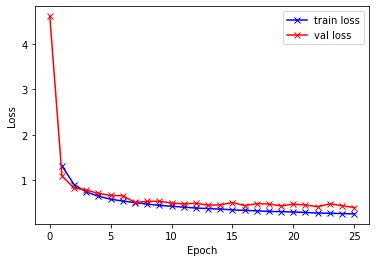

In [48]:
plot_loss(history)

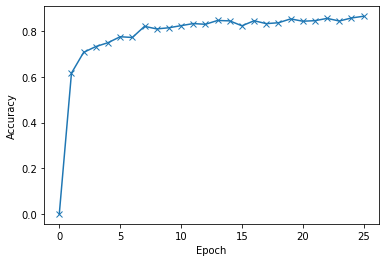

In [49]:
plot_acc(history)

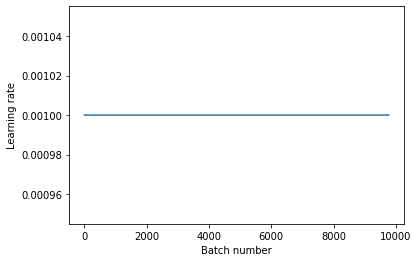

In [50]:
plot_lrs(history)

In [51]:
torch.save(model.state_dict(), 'cifar100-resnet.pth')
jovian.log_hyperparams(arch='Resnet', 
                       epochs=epochs, 
                       lr=max_lr, 
                       scheduler='one-cycle', 
                       weight_decay=weight_decay, 
                       grad_clip=grad_clip,
                       opt=optimizer.__name__)
jovian.log_metrics(val_loss=history[-1]['val_loss'], 
                   val_acc=history[-1]['val_acc'],
                   train_loss=history[-1]['train_loss'])
jovian.commit(project=project_name,outputs=['cifar100-resnet.pth'])

NameError: name 'jovian' is not defined